In [11]:
import pandas as pd
import numpy as np

In [12]:
path = "data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv.zip"
df = pd.read_csv(path)

In [13]:
print(df.shape)
df.head()

(225745, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [14]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:", df.isnull().sum().sum())


Column names:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count

In [15]:
# Clean column names
df.columns = df.columns.str.strip()

# Check attack labels
print(df["Label"].value_counts())

# Check infinite values
import numpy as np

print("Infinite values:", np.isinf(df.select_dtypes(include="number")).sum().sum())


Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64
Infinite values: 64


In [16]:
# Replace infinite values with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove rows containing missing values
df.dropna(inplace=True)

# Separate features and labels
X = df.drop(columns=["Label"])
y = df["Label"].str.strip()

print("Cleaned dataset:", X.shape)
print("\nLabels:\n", y.value_counts())
print("\nRemaining missing values:", X.isna().sum().sum())


Cleaned dataset: (225711, 78)

Labels:
 Label
DDoS      128025
BENIGN     97686
Name: count, dtype: int64

Remaining missing values: 0


In [17]:
from sklearn.model_selection import train_test_split

# Separate benign and attack traffic
X_benign = X[y == "BENIGN"]
X_ddos = X[y == "DDoS"]

# Split benign data
X_train, X_benign_test = train_test_split(
    X_benign,
    test_size=0.2,
    random_state=42
)

# Combine unseen benign and DDoS traffic for testing
X_test = pd.concat([X_benign_test, X_ddos])
y_test = pd.concat([
    pd.Series(0, index=X_benign_test.index),
    pd.Series(1, index=X_ddos.index)
])

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Normal training data only:", True)


Training samples: 78148
Testing samples: 147563
Normal training data only: True


In [18]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Handle any remaining invalid values and train
model = make_pipeline(
    SimpleImputer(strategy="median"),
    IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    )
)

model.fit(X_train)

print("Isolation Forest trained successfully!")


Isolation Forest trained successfully!


In [19]:
from sklearn.metrics import classification_report, confusion_matrix

# Predict: -1 = anomaly, 1 = normal
predictions = model.predict(X_test)

# Convert to labels: 1 = DDoS, 0 = BENIGN
y_pred = (predictions == -1).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["BENIGN", "DDoS"]
))

Confusion Matrix:
[[16948  2590]
 [61491 66534]]

Classification Report:
              precision    recall  f1-score   support

      BENIGN       0.22      0.87      0.35     19538
        DDoS       0.96      0.52      0.67    128025

    accuracy                           0.57    147563
   macro avg       0.59      0.69      0.51    147563
weighted avg       0.86      0.57      0.63    147563



In [20]:
# Get anomaly scores: lower generally means more anomalous
scores = model.decision_function(X_test)

print("Benign traffic scores:")
print(pd.Series(scores[y_test.to_numpy() == 0]).describe())

print("\nDDoS traffic scores:")
print(pd.Series(scores[y_test.to_numpy() == 1]).describe())

Benign traffic scores:
count    19538.000000
mean         0.102334
std          0.074732
min         -0.251191
25%          0.057813
50%          0.135256
75%          0.159380
max          0.172322
dtype: float64

DDoS traffic scores:
count    128025.000000
mean          0.029546
std           0.087783
min          -0.145521
25%          -0.017621
50%          -0.000865
75%           0.127410
max           0.169582
dtype: float64


In [21]:
from sklearn.metrics import confusion_matrix, classification_report

for threshold in [0.00, 0.02, 0.04, 0.06]:
    y_pred_tuned = (scores < threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print(confusion_matrix(y_test, y_pred_tuned))
    print(classification_report(
        y_test, y_pred_tuned,
        target_names=["BENIGN", "DDoS"],
        zero_division=0
    ))
    


Threshold: 0.0
[[16948  2590]
 [61491 66534]]
              precision    recall  f1-score   support

      BENIGN       0.22      0.87      0.35     19538
        DDoS       0.96      0.52      0.67    128025

    accuracy                           0.57    147563
   macro avg       0.59      0.69      0.51    147563
weighted avg       0.86      0.57      0.63    147563


Threshold: 0.02
[[16401  3137]
 [46645 81380]]
              precision    recall  f1-score   support

      BENIGN       0.26      0.84      0.40     19538
        DDoS       0.96      0.64      0.77    128025

    accuracy                           0.66    147563
   macro avg       0.61      0.74      0.58    147563
weighted avg       0.87      0.66      0.72    147563


Threshold: 0.04
[[15588  3950]
 [46593 81432]]
              precision    recall  f1-score   support

      BENIGN       0.25      0.80      0.38     19538
        DDoS       0.95      0.64      0.76    128025

    accuracy                           

In [22]:
print(X_train.dtypes.value_counts())
print("\nConstant columns:", (X_train.nunique() <= 1).sum())
print("\nDuplicate columns:", X_train.T.duplicated().sum())

int64      54
float64    24
Name: count, dtype: int64

Constant columns: 10

Duplicate columns: 18


In [23]:
# Identify constant columns using training data only
constant_cols = X_train.columns[X_train.nunique() <= 1]

# Remove constant columns
X_train_clean = X_train.drop(columns=constant_cols)

# Remove duplicate columns using training data only
X_train_clean = X_train_clean.loc[
    :, ~X_train_clean.T.duplicated()
]

# Apply the same columns to test data
X_test_clean = X_test[X_train_clean.columns]

print("Original features:", X_train.shape[1])
print("Cleaned features:", X_train_clean.shape[1]) 

Original features: 78
Cleaned features: 59


In [24]:
print("Available features:\n")

for i, col in enumerate(X_train_clean.columns, start=1):
    print(f"{i:2}. {col}")

Available features:

 1. Destination Port
 2. Flow Duration
 3. Total Fwd Packets
 4. Total Backward Packets
 5. Total Length of Fwd Packets
 6. Total Length of Bwd Packets
 7. Fwd Packet Length Max
 8. Fwd Packet Length Min
 9. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Fwd Header Length
33. Bwd Header Length
34. Fwd Packets/s
35. Bwd Packets/s
36. Min Packet Length
37. Max Packet Length
38. Packet Length Mean
39. Packet Length Std
40. Packet Length Variance
41. FIN Flag Count
42. RST Flag Count
43. PSH Flag Count
44. ACK Flag Count
45. URG Flag Count
46. Down/Up Ratio
47. Average Packet 

In [25]:
selected_features = [
"Destination Port",
"Flow Duration",
"Total Fwd Packets",
"Total Backward Packets",
"Total Length of Fwd Packets",
"Total Length of Bwd Packets",
"Flow Bytes/s",
"Flow Packets/s",
"Flow IAT Mean",
"Fwd Packets/s",
"Bwd Packets/s",
"Packet Length Mean",
"Packet Length Std",
"SYN Flag Count",
"ACK Flag Count"
]

In [26]:
selected_features = [
col for col in selected_features
if col in X_train_clean.columns
]

X_train_selected = X_train_clean[selected_features]
X_test_selected = X_test_clean[selected_features]

print("Selected features:", len(selected_features))
print(selected_features)

Selected features: 14
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Mean', 'Packet Length Std', 'ACK Flag Count']


In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest

model_selected = make_pipeline(
    SimpleImputer(strategy="median"),
    IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    )
)

model_selected.fit(X_train_selected)

print("Model trained on", len(selected_features), "features!")

Model trained on 14 features!


In [28]:
from sklearn.metrics import classification_report, confusion_matrix

scores_selected = model_selected.decision_function(X_test_selected)

threshold = 0.02
pred_selected = (scores_selected < threshold).astype(int)

print(confusion_matrix(y_test, pred_selected))
print(classification_report(
    y_test,
    pred_selected,
    target_names=["BENIGN", "DDoS"],
    zero_division=0
))

[[15313  4225]
 [49275 78750]]
              precision    recall  f1-score   support

      BENIGN       0.24      0.78      0.36     19538
        DDoS       0.95      0.62      0.75    128025

    accuracy                           0.64    147563
   macro avg       0.59      0.70      0.56    147563
weighted avg       0.85      0.64      0.70    147563



In [29]:
# Inspect the selected features for extreme values
print(
    X_train_selected[
        ["Flow Bytes/s", "Flow Packets/s", "Flow Duration"]
    ].describe(percentiles=[0.50, 0.90, 0.95, 0.99]).T
)

                  count          mean           std         min  \
Flow Bytes/s    78148.0  1.314201e+06  2.652022e+07 -12000000.0   
Flow Packets/s  78148.0  3.266957e+04  1.727593e+05  -2000000.0   
Flow Duration   78148.0  1.529894e+07  3.215323e+07        -1.0   

                          50%           90%           95%           99%  \
Flow Bytes/s      2181.930454  1.271154e+06  1.721113e+06  1.200000e+07   
Flow Packets/s      27.138305  2.424242e+04  4.545455e+04  6.666667e+05   
Flow Duration   174257.000000  8.022108e+07  9.806484e+07  1.175860e+08   

                         max  
Flow Bytes/s    2.070000e+09  
Flow Packets/s  3.000000e+06  
Flow Duration   1.199999e+08  


In [30]:
for col in ["Flow Bytes/s", "Flow Packets/s", "Flow Duration"]:
    print(f"\n{col}")
    print("Negative values:", (X_train_selected[col] < 0).sum())
    print("Zero values:", (X_train_selected[col] == 0).sum())


Flow Bytes/s
Negative values: 2
Zero values: 4038

Flow Packets/s
Negative values: 2
Zero values: 0

Flow Duration
Negative values: 2
Zero values: 0


In [31]:
import numpy as np

invalid_features = [
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow Duration"
]

X_train_fixed = X_train_selected.copy()
X_test_fixed = X_test_selected.copy()

for col in invalid_features:
    X_train_fixed.loc[X_train_fixed[col] < 0, col] = np.nan
    X_test_fixed.loc[X_test_fixed[col] < 0, col] = np.nan

print("Invalid training values:")
print(X_train_fixed[invalid_features].isna().sum())

print("\nInvalid test values:")
print(X_test_fixed[invalid_features].isna().sum())

Invalid training values:
Flow Bytes/s      2
Flow Packets/s    2
Flow Duration     2
dtype: int64

Invalid test values:
Flow Bytes/s      0
Flow Packets/s    0
Flow Duration     0
dtype: int64


In [32]:
model_fixed = make_pipeline(
    SimpleImputer(strategy="median"),
    IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    )
)

model_fixed.fit(X_train_fixed)

scores_fixed = model_fixed.decision_function(X_test_fixed)
pred_fixed = (scores_fixed < 0.02).astype(int)

print(confusion_matrix(y_test, pred_fixed))
print(classification_report(
    y_test,
    pred_fixed,
    target_names=["BENIGN", "DDoS"],
    zero_division=0
))

[[15313  4225]
 [49275 78750]]
              precision    recall  f1-score   support

      BENIGN       0.24      0.78      0.36     19538
        DDoS       0.95      0.62      0.75    128025

    accuracy                           0.64    147563
   macro avg       0.59      0.70      0.56    147563
weighted avg       0.85      0.64      0.70    147563



In [33]:
from sklearn.preprocessing import StandardScaler

model_scaled = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    )
)

model_scaled.fit(X_train_fixed)

scores_scaled = model_scaled.decision_function(X_test_fixed)
pred_scaled = (scores_scaled < 0.02).astype(int)

print(confusion_matrix(y_test, pred_scaled))
print(classification_report(
    y_test,
    pred_scaled,
    target_names=["BENIGN", "DDoS"],
    zero_division=0
))

[[15293  4245]
 [49288 78737]]
              precision    recall  f1-score   support

      BENIGN       0.24      0.78      0.36     19538
        DDoS       0.95      0.62      0.75    128025

    accuracy                           0.64    147563
   macro avg       0.59      0.70      0.55    147563
weighted avg       0.85      0.64      0.70    147563



In [34]:
analysis_df = X.copy()
analysis_df["Label"] = y

features_to_inspect = [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean"
]

for feature in features_to_inspect:
    print(f"\n--- {feature} ---")
    print(
        analysis_df.groupby("Label")[feature]
        .agg(["median", "mean", "std"])
        .round(2)
    )


--- Destination Port ---
        median      mean       std
Label                             
BENIGN   443.0  20403.51  25828.45
DDoS      80.0     81.23    267.41

--- Flow Duration ---
           median         mean          std
Label                                      
BENIGN   172209.0  15311276.94  32162806.86
DDoS    1878984.0  16955856.65  31012784.77

--- Total Fwd Packets ---
        median  mean    std
Label                      
BENIGN     2.0  5.40  23.33
DDoS       4.0  4.47   1.90

--- Total Backward Packets ---
        median  mean    std
Label                      
BENIGN     2.0  6.30  32.86
DDoS       4.0  3.26   2.55

--- Flow Bytes/s ---
         median        mean          std
Label                                   
BENIGN  2220.04  1272497.80  25595420.87
DDoS     160.10    61117.88   1471895.27

--- Flow Packets/s ---
        median      mean        std
Label                              
BENIGN   27.46  32678.94  172868.68
DDoS      2.59    172.79    9961.5

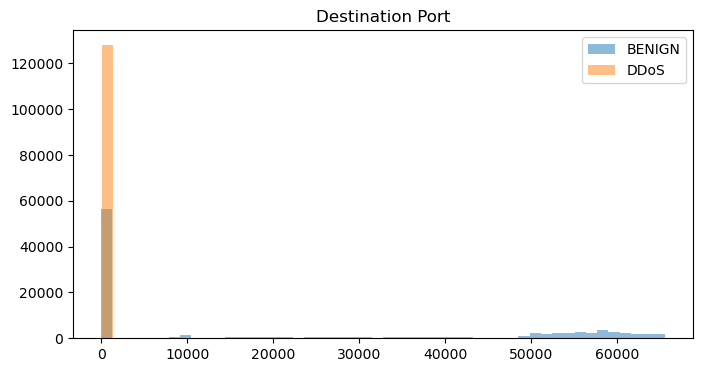

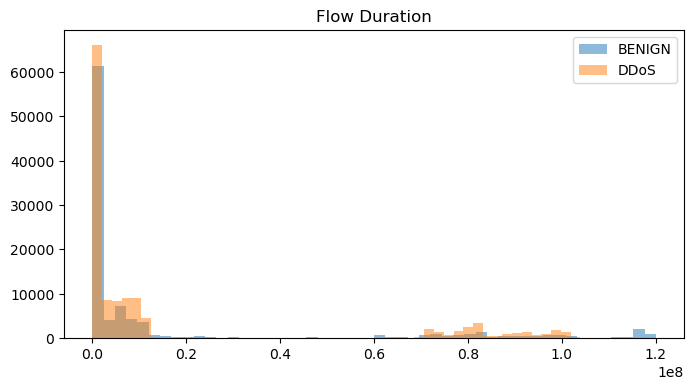

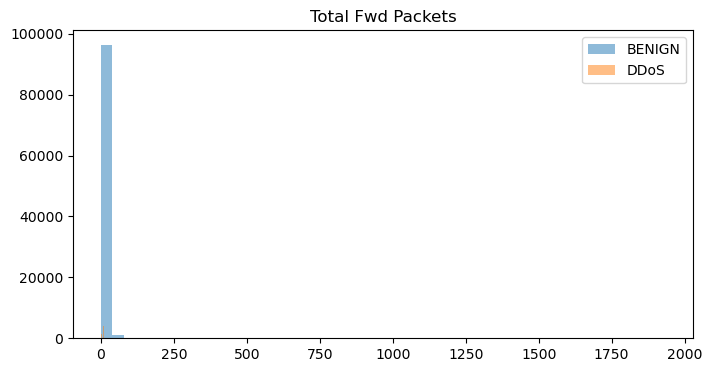

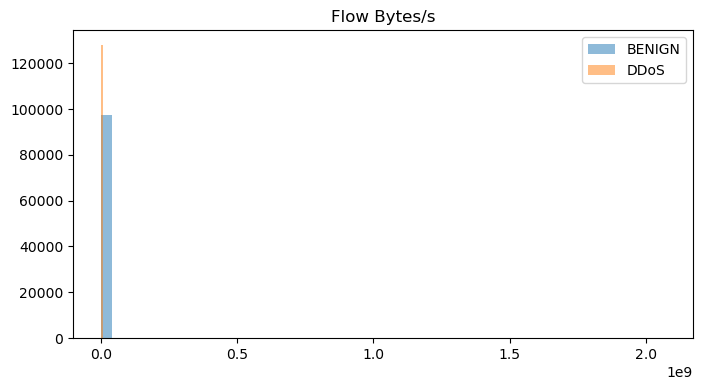

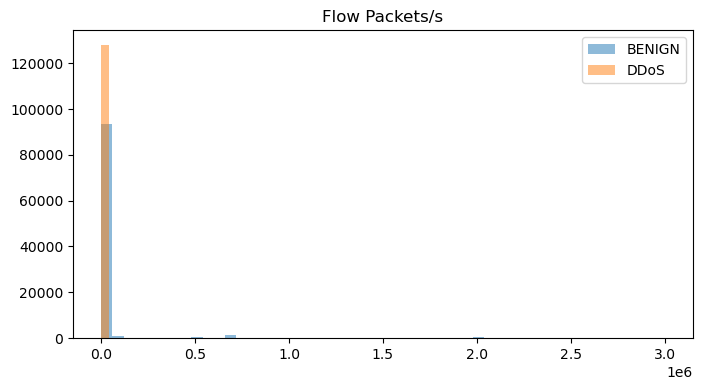

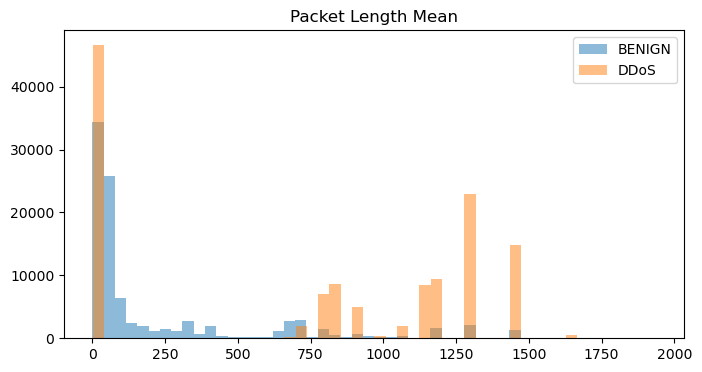

In [35]:
import matplotlib.pyplot as plt

features = [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean"
]

for feature in features:
    plt.figure(figsize=(8, 4))

    for label in ["BENIGN", "DDoS"]:
        values = analysis_df.loc[
            analysis_df["Label"] == label, feature
        ]
        values = values[values >= 0]

        plt.hist(values, bins=50, alpha=0.5, label=label)

    plt.title(feature)
    plt.legend()
    plt.show()

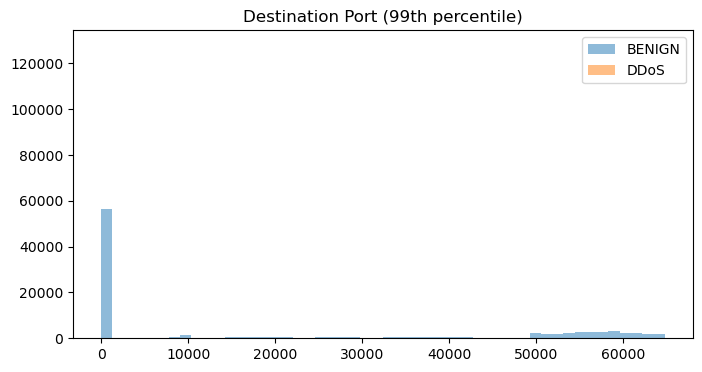

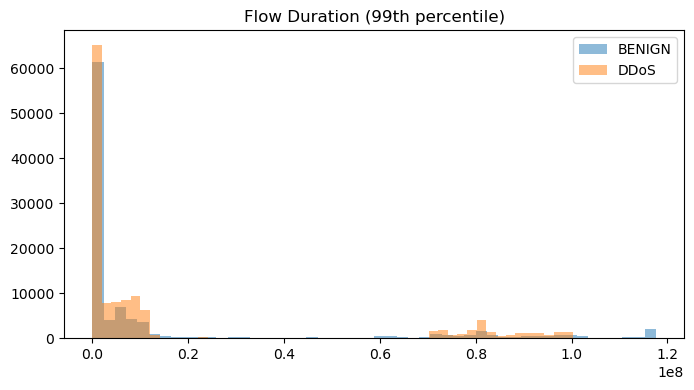

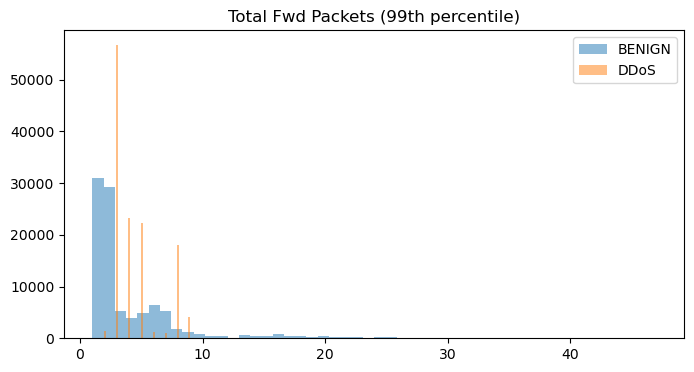

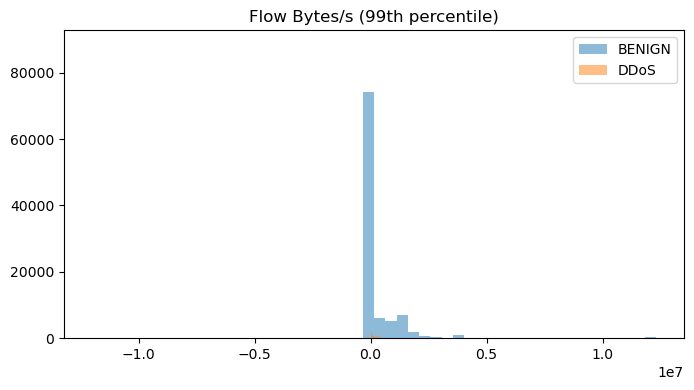

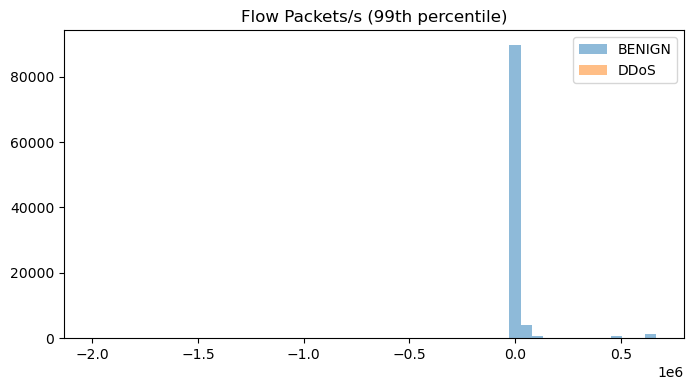

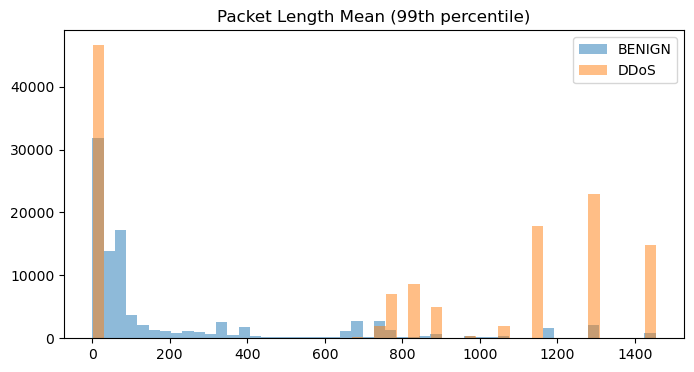

In [36]:
for feature in features:
    plt.figure(figsize=(8, 4))

    for label in ["BENIGN", "DDoS"]:
        values = analysis_df.loc[
            analysis_df["Label"] == label, feature
        ].dropna()

        # Display only values below the 99th percentile
        upper = values.quantile(0.99)
        values = values[values <= upper]

        plt.hist(values, bins=50, alpha=0.5, label=label)

    plt.title(f"{feature} (99th percentile)")
    plt.legend()
    plt.show()

In [37]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
import numpy as np

X_sample = X_test_fixed.sample(n=5000, random_state=42)
y_sample = y_test.loc[X_sample.index]

def anomaly_score(estimator, X, y):
    scores = -estimator.decision_function(X)
    return roc_auc_score(y, scores)

result = permutation_importance(
    model_fixed,
    X_sample,
    y_sample,
    scoring=anomaly_score,
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance = pd.Series(
    result.importances_mean,
    index=X_sample.columns
).sort_values(ascending=False)

print(importance.head(15))

Packet Length Std              0.123177
Packet Length Mean             0.093506
ACK Flag Count                 0.092828
Flow IAT Mean                  0.064927
Total Length of Bwd Packets    0.063326
Total Fwd Packets              0.038079
Flow Duration                  0.025020
Total Backward Packets         0.022835
Total Length of Fwd Packets    0.008212
Fwd Packets/s                  0.006719
Flow Packets/s                 0.002722
Destination Port               0.001909
Flow Bytes/s                  -0.001355
Bwd Packets/s                 -0.002498
dtype: float64


In [38]:
top_features = importance.head(8).index.tolist()

X_train_top = X_train_fixed[top_features]
X_test_top = X_test_fixed[top_features]

model_top = make_pipeline(
    SimpleImputer(strategy="median"),
    IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    )
)

model_top.fit(X_train_top)

scores_top = model_top.decision_function(X_test_top)
pred_top = (scores_top < 0.02).astype(int)

print(confusion_matrix(y_test, pred_top))
print(classification_report(
    y_test, pred_top,
    target_names=["BENIGN", "DDoS"]
))

[[14445  5093]
 [43250 84775]]
              precision    recall  f1-score   support

      BENIGN       0.25      0.74      0.37     19538
        DDoS       0.94      0.66      0.78    128025

    accuracy                           0.67    147563
   macro avg       0.60      0.70      0.58    147563
weighted avg       0.85      0.67      0.72    147563



In [39]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(model_top, "models/isolation_forest.joblib")
joblib.dump(top_features, "models/features.joblib")

print("Model and feature list saved!")
print("Features:", top_features)

Model and feature list saved!
Features: ['Packet Length Std', 'Packet Length Mean', 'ACK Flag Count', 'Flow IAT Mean', 'Total Length of Bwd Packets', 'Total Fwd Packets', 'Flow Duration', 'Total Backward Packets']


In [40]:
import os

print(os.listdir("models"))

['isolation_forest.joblib', 'severity_policy.json', 'features.joblib']


In [41]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

top_features = importance.head(8).index.tolist()

model_top = make_pipeline(
    SimpleImputer(strategy="median"),
    IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    )
)

model_top.fit(X_train_fixed[top_features])

print("Model trained successfully!")

Model trained successfully!


In [42]:
import os

print(os.listdir("models"))

['isolation_forest.joblib', 'severity_policy.json', 'features.joblib']


In [43]:
path = "data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv.zip"
df_new = pd.read_csv(path)

In [44]:
print(df_new.columns.tolist())

[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' URG Flag 

In [45]:
print(df_new.shape)
print(df_new.columns.tolist()[:10])
print(df_new.columns.tolist()[-10:])

(225745, 79)
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std']
[' min_seg_size_forward', 'Active Mean', ' Active Std', ' Active Max', ' Active Min', 'Idle Mean', ' Idle Std', ' Idle Max', ' Idle Min', ' Label']


In [46]:
print(confusion_matrix(y_test, pred_top))

[[14445  5093]
 [43250 84775]]


In [47]:
print(classification_report(
    y_test, pred_top,
    target_names=["BENIGN", "Attack"]
))

              precision    recall  f1-score   support

      BENIGN       0.25      0.74      0.37     19538
      Attack       0.94      0.66      0.78    128025

    accuracy                           0.67    147563
   macro avg       0.60      0.70      0.58    147563
weighted avg       0.85      0.67      0.72    147563

